In [1]:
import matplotlib.pyplot as plt
import os
import numpy as np
from monai.transforms import LoadImage, EnsureChannelFirst, Orientation, Compose
from monai.bundle import ConfigParser, download
import torch


In [2]:
dicom_file_path = 'data/normal_cases/AG 519880_37F/DICOM/EXP00000/'
# dicom_file_path = 'data/normal_cases/ASJ 05633540_68F/DICOM/EXP00000/'

image_loader = LoadImage(image_only=True)
CT = image_loader(dicom_file_path)

CT.meta

{'00200037': {'vr': 'DS', 'Value': [1.0, 0.0, 0.0, 0.0, 1.0, 0.0]},
 '00200032': {'vr': 'DS', 'Value': [-182.2, -184.2, 58.55]},
 '00280030': {'vr': 'DS', 'Value': [0.738281, 0.738281, 0.625]},
 'spacing': array([0.738281, 0.738281, 0.625   ]),
 'lastImagePositionPatient': array([-182.2, -184.2, -262.7]),
 spatial_shape: (512, 512, 515),
 space: RAS,
 original_affine: array([[ -0.738281,   0.      ,   0.      , 182.2     ],
        [  0.      ,  -0.738281,   0.      , 184.2     ],
        [  0.      ,   0.      ,  -0.625   ,  58.55    ],
        [  0.      ,   0.      ,   0.      ,   1.      ]]),
 affine: tensor([[ -0.7383,   0.0000,   0.0000, 182.2000],
         [  0.0000,  -0.7383,   0.0000, 184.2000],
         [  0.0000,   0.0000,  -0.6250,  58.5500],
         [  0.0000,   0.0000,   0.0000,   1.0000]], dtype=torch.float64),
 original_channel_dim: nan,
 'filename_or_obj': 'data/normal_cases/AG 519880_37F/DICOM/EXP00000'}

In [3]:
CT.shape

torch.Size([512, 512, 515])

In [4]:
CT_coronal_slice = CT[:,256].cpu().numpy()

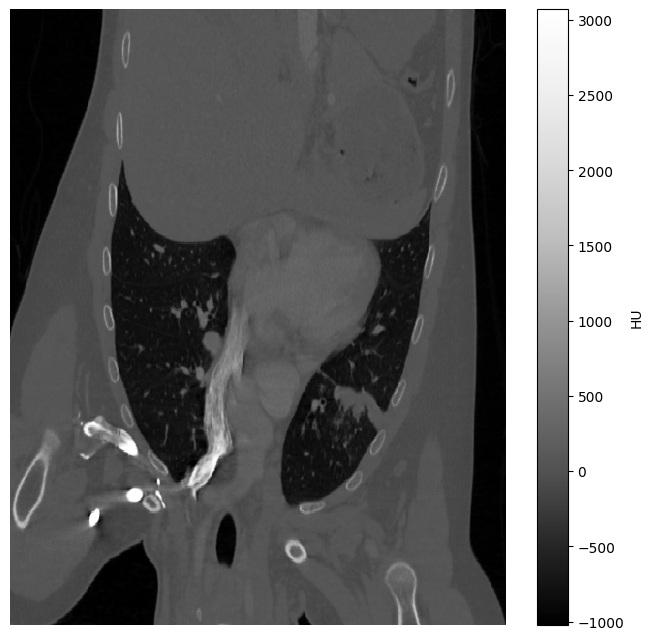

In [5]:
plt.figure(figsize=(8,8))
plt.pcolormesh(CT_coronal_slice.T, cmap='Greys_r')
plt.colorbar(label='HU')
plt.axis('off')
plt.show()

In [6]:
preprocessing_pipeline = Compose([
    LoadImage(image_only=True),
    EnsureChannelFirst(),
    Orientation(axcodes='LPS')
])

In [7]:
CT = preprocessing_pipeline(dicom_file_path)
CT_coronal_slice = CT[0, :, 256].cpu().numpy()

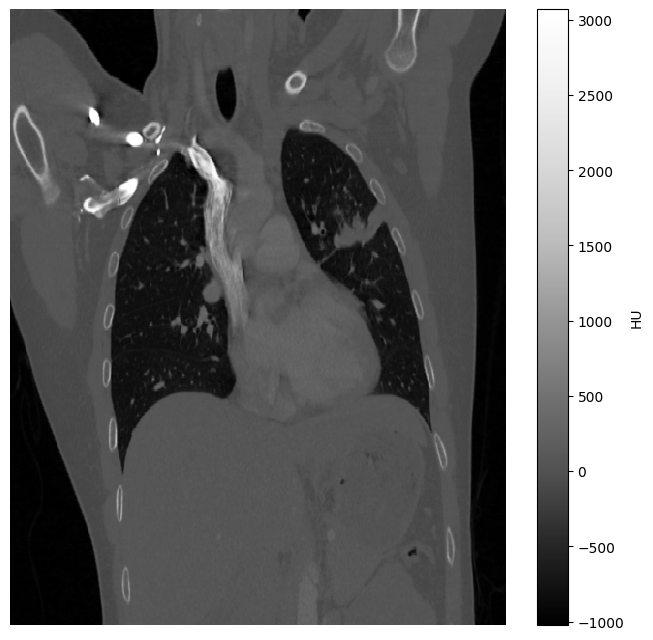

In [8]:
plt.figure(figsize=(8,8))
plt.pcolormesh(CT_coronal_slice.T, cmap='Greys_r')
plt.colorbar(label='HU')
plt.axis('off')
plt.show()

In [9]:
model_name = "wholeBody_ct_segmentation"
data_directory = 'data/'
# download(name=model_name, bundle_dir=data_directory)

In [10]:
model_path = os.path.join(data_directory, 'wholeBody_ct_segmentation', 'models', 'model_lowres.pt')
config_path = os.path.join(data_directory, 'wholeBody_ct_segmentation', 'configs', 'inference.json')

In [11]:
config = ConfigParser()
config.read_config(config_path)

In [12]:
preprocessor = config.get_parsed_content("preprocessing")

model = config.get_parsed_content("network")
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model.eval()

inferer = config.get_parsed_content("inferer")

postprocessor = config.get_parsed_content("postprocessing")

/var/folders/jm/k37qm_7n7dj5fp2rnwhd32y80000gn/T/ipykernel_3289/455294333.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, ma

In [13]:
output = preprocessor({'image': dicom_file_path}) 

with torch.no_grad():
    # Have to add additional batch dimension to feed into model
    output['pred'] = inferer(output['image'].unsqueeze(0), network=model)
    
# Remove batch dimension in image and prediction
output['pred'] = output['pred'][0]
output['image'] = output['image'][0]

print("Unique values before postprocessing:", torch.unique(output['pred']))

# Apply postprocessing to data
output = postprocessor(output)

print("Unique values after postprocessing:", torch.unique(output['pred']))


segmentation = torch.flip(output['pred'][0], dims=[2])
segmentation = segmentation.cpu().numpy()


Unique values before postprocessing: metatensor([-22.5227, -22.1510, -22.0635,  ...,  17.7059,  17.7062,  17.7108])
2024-11-05 15:26:30,108 INFO image_writer.py:197 - writing: eval/EXP00000/EXP00000_trans.nii.gz
Unique values after postprocessing: metatensor([ 0.,  5., 13., 44., 46.])


In [14]:
segmentation.shape

(512, 512, 515)

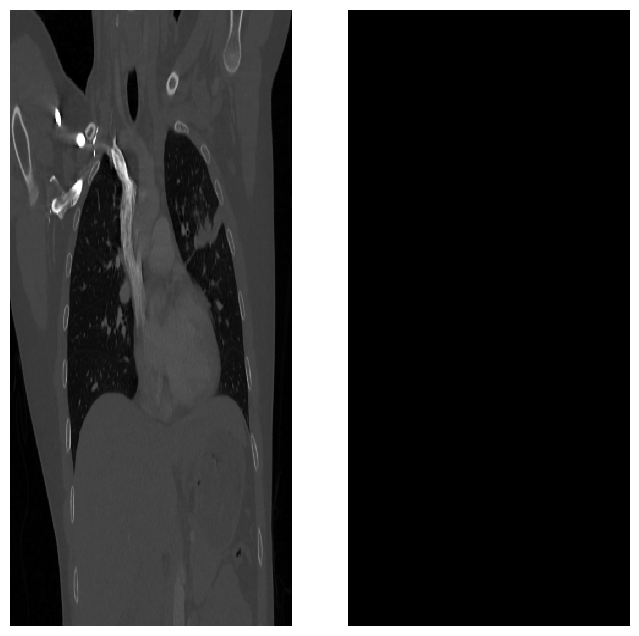

In [22]:
slice_num = 256
CT_coronal_slice = CT[0,:, slice_num].cpu().numpy()
segmentation_coronal_slice = segmentation[:, slice_num]

plt.subplots(1,2,figsize=(8,8))
plt.subplot(121)
plt.pcolormesh(CT_coronal_slice.T, cmap='grey')
plt.axis('off')
plt.subplot(122)
plt.pcolormesh(segmentation_coronal_slice.T, cmap='nipy_spectral')
plt.axis('off')
plt.show()


In [52]:
import nibabel as nib
from totalsegmentator.python_api import totalsegmentator


# option 1: provide input and output as file paths
output_directory = "data/segment_eval_output"
output_image = totalsegmentator(dicom_file_path, output_directory, license_number="aca_BWYHC6UQQFDU8A", task="heartchambers_highres")

# option 2: provide input and output as nifti image objects
# input_img = nib.load(dicom_file_path)
# output_img = totalsegmentator(input_img)
# print(output_img)
# nib.save(output_img, data_directory)

No GPU detected. Running on CPU. This can be very slow. The '--fast' or the `--roi_subset` option can help to reduce runtime.

If you use this tool please cite: https://pubs.rsna.org/doi/10.1148/ryai.230024



Downloading: 100%|██████████| 230M/230M [01:04<00:00, 3.55MB/s] 


Download finished. Extracting...
Generating rough segmentation for cropping...


Downloading: 100%|██████████| 135M/135M [00:07<00:00, 18.0MB/s] 


Download finished. Extracting...
Converting dicom to nifti...
  found image with shape (512, 512, 515)
Resampling...
  Resampled in 4.04s
Predicting...


...

Python(6760) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6761) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6762) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6763) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6764) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6765) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6766) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6767) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6768) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6769) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(6770) MallocStackLoggin

  Predicted in 1951.18s
Saving segmentations...


Python(9247) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(9248) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(9249) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(9250) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(9251) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(9252) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


  0%|          | 0/7 [00:00<?, ?it/s]

Creating heart_myocardium.nii.gz

Creating heart_atrium_left.nii.gzCreating heart_ventricle_left.nii.gz
Creating heart_atrium_right.nii.gzCreating heart_ventricle_right.nii.gz

Creating aorta.nii.gz
Creating pulmonary_artery.nii.gz
  Saved in 6.72s


In [ ]:
%matplotlib inline
slice_num = 100

plt.imshow(output_image[:, :, slice_num], cmap='nipy_spectral')
plt.title(f"Slice {slice_num}")
plt.axis('off')
plt.show()

TypeError: Cannot slice image objects; consider using `img.slicer[slice]` to generate a sliced image (see documentation for caveats) or slicing image array data with `img.dataobj[slice]` or `img.get_fdata()[slice]`

<class 'monai.data.meta_tensor.MetaTensor'>
torch.Size([512, 512, 515])


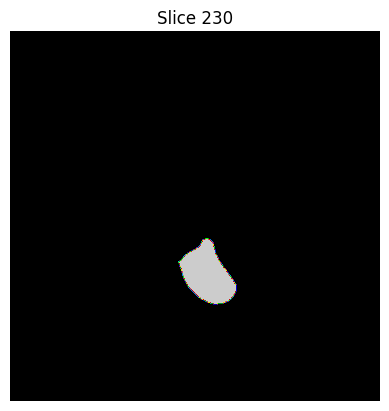

In [59]:


# Create a LoadImage transform instance
# load_image = LoadImage(image_only=True)

# Load the image
image = image_loader(f"data/segment_eval_output/heart_ventricle_left.nii.gz")


# Check the image type and shape
print(type(image))  # Should be a PyTorch Tensor or NumPy array
print(image.shape)  # Shows the dimensions of the loaded image

slice_num = 230

# Display a slice of the image
plt.imshow(image[:, :, slice_num], cmap='nipy_spectral')
plt.title(f"Slice {slice_num}")
plt.axis('off')
plt.show()